# Phần Đức (1/2) — Feature Engineering Luồng B

- **Đầu vào:** `X_train_raw.csv`, `X_test_raw.csv` do Mạnh chia (không chia lại).
- **Đầu ra:** `X_train_B.csv`, `X_test_B.csv` (17 đặc trưng).
- Mọi phân tích để chọn đặc trưng chỉ dùng **tập Train**.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "config.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.feature_engineering_b import PROCESSED_DIR, tao_dac_trung_B

X_train = pd.read_csv(PROCESSED_DIR / "X_train_raw.csv")
X_test = pd.read_csv(PROCESSED_DIR / "X_test_raw.csv")
y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv")["Churn"]

df = X_train.copy()
df["churn"] = (y_train == "Yes").astype(int)   # 1 = rời bỏ
print("X_train:", X_train.shape, "| X_test:", X_test.shape)


def ty_le_churn(cot):
    """Tỷ lệ Churn (%) theo từng giá trị của cột (chỉ trên Train)."""
    return (df.groupby(cot, observed=True)["churn"].mean() * 100).round(1)

X_train: (5634, 19) | X_test: (1409, 19)


## 1. Phân tích trên Train để chọn đặc trưng

### 1.1. `TotalCharges` bị thiếu

In [2]:
thieu = df[df["TotalCharges"].isna()]
print("Số dòng thiếu TotalCharges:", len(thieu))
print("tenure của các dòng này:", thieu["tenure"].unique())
print("Median TotalCharges (Luồng A dùng để điền):", df["TotalCharges"].median())

Số dòng thiếu TotalCharges: 8
tenure của các dòng này: [0]
Median TotalCharges (Luồng A dùng để điền): 1398.125


Cả 8 dòng thiếu đều có `tenure = 0`: đây là **khách hàng mới, chưa có hóa đơn**.
Vì vậy Luồng B điền `TotalCharges = tenure × MonthlyCharges = 0`, hợp lý hơn điền median 1.398 như Luồng A.

### 1.2. Cột ít thông tin

In [3]:
print("gender:", ty_le_churn("gender").to_dict())

co_internet = df[df["InternetService"] != "No"]
for cot in ["StreamingTV", "StreamingMovies"]:
    print(cot, "(khách có Internet):", (co_internet.groupby(cot)["churn"].mean() * 100).round(1).to_dict())

gender: {'Female': 26.6, 'Male': 26.4}
StreamingTV (khách có Internet): {'No': 33.1, 'Yes': 30.5}
StreamingMovies (khách có Internet): {'No': 33.6, 'Yes': 30.0}


- `gender`: Nữ 26,6% và Nam 26,4% — gần như bằng nhau → **bỏ**.
- `StreamingTV`, `StreamingMovies`: trong nhóm có Internet chỉ chênh khoảng 3 điểm phần trăm → **bỏ**.

### 1.3. Đếm số dịch vụ bảo vệ còn thiếu

Thay vì One-Hot 4 dịch vụ `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport` (12 cột ở Luồng A),
đếm xem khách hàng **còn thiếu bao nhiêu dịch vụ** (giá trị `"No"`).

{0: 6.8, 1: 12.0, 2: 24.2, 3: 39.2, 4: 56.9}


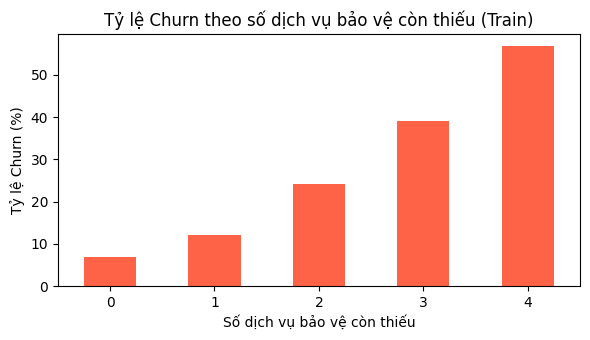

In [4]:
so_dv_thieu = (df[["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]] == "No").sum(axis=1)
bang = ty_le_churn(so_dv_thieu)
print(bang.to_dict())

ax = bang.plot.bar(color="tomato", rot=0, figsize=(6, 3.5))
ax.set_xlabel("Số dịch vụ bảo vệ còn thiếu")
ax.set_ylabel("Tỷ lệ Churn (%)")
ax.set_title("Tỷ lệ Churn theo số dịch vụ bảo vệ còn thiếu (Train)")
plt.tight_layout()
(PROJECT_ROOT / "report" / "figures").mkdir(parents=True, exist_ok=True)
plt.savefig(PROJECT_ROOT / "report" / "figures" / "fe_missing_protection.png", dpi=150)
plt.show()

Tỷ lệ Churn tăng đều: 6,8% → 12,0% → 24,2% → 39,2% → 56,9%. Một cột số thể hiện rõ xu hướng này.

### 1.4. Nhóm thời gian sử dụng và loại hợp đồng

In [5]:
nhom_tenure = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", ">48"])
print("Theo nhóm tenure:", ty_le_churn(nhom_tenure).to_dict())
print("Theo Contract:", ty_le_churn("Contract").to_dict())

Theo nhóm tenure: {'0-12': 47.3, '13-24': 28.6, '25-48': 20.2, '>48': 9.9}
Theo Contract: {'Month-to-month': 42.7, 'One year': 11.1, 'Two year': 2.9}


Tỷ lệ Churn giảm dần theo thời gian sử dụng (47,3% → 28,6% → 20,2% → 9,9%) và theo độ dài hợp đồng
(42,7% → 11,1% → 2,9%). Hai biến có thứ tự tự nhiên nên mã hóa thành số: `TenureGroup` (0–3), `ContractLength` (0, 1, 2 năm).

### 1.5. Đặc trưng tương tác

In [6]:
hop_dong_thang = df["Contract"] == "Month-to-month"
print("Tháng + Fiber optic:", ty_le_churn(hop_dong_thang & (df["InternetService"] == "Fiber optic")).to_dict())
print("Tháng + Electronic check:", ty_le_churn(hop_dong_thang & (df["PaymentMethod"] == "Electronic check")).to_dict())
print("PaymentMethod:", ty_le_churn("PaymentMethod").to_dict())

Tháng + Fiber optic: {False: 14.1, True: 55.1}
Tháng + Electronic check: {False: 16.6, True: 54.2}
PaymentMethod: {'Bank transfer (automatic)': 16.2, 'Credit card (automatic)': 14.9, 'Electronic check': 45.7, 'Mailed check': 19.3}


- Hợp đồng theo tháng **và** Fiber optic: 55,1% (phần còn lại 14,1%).
- Hợp đồng theo tháng **và** Electronic check: 54,2% (phần còn lại 16,6%).
- Bank transfer và Credit card (đều tự động) có tỷ lệ gần nhau (16,2% và 14,9%) → gộp thành `IsAutoPayment`.

## 2. Tạo Luồng B

Hàm `tao_dac_trung_B` trong `src/feature_engineering_b.py` cài đặt các quyết định trên.

In [7]:
X_train_B = tao_dac_trung_B(X_train)
X_test_B = tao_dac_trung_B(X_test)

print("X_train_B:", X_train_B.shape, "| X_test_B:", X_test_B.shape)
print("Giá trị thiếu:", X_train_B.isna().sum().sum(), X_test_B.isna().sum().sum())
X_train_B.head()

X_train_B: (5634, 17) | X_test_B: (1409, 17)
Giá trị thiếu: 0 0


,SeniorCitizen,Partner,Dependents,PaperlessBilling,PhoneLines,ContractLength,tenure,TenureGroup,MonthlyCharges,LogTotalCharges,HasInternet,IsFiber,IsElectronicCheck,IsAutoPayment,MissingProtectionCount,MonthToMonth_Fiber,MonthToMonth_ElectronicCheck
0,0,0,0,0,0,0,35,2,49.20,7.439941,1,0,1,0,3,0,1
1,0,1,1,0,1,0,15,1,75.10,7.049732,1,1,0,0,3,1,0
2,0,1,1,0,0,2,13,1,40.55,6.382408,1,0,0,0,1,0,0
3,0,1,0,1,1,2,26,2,73.50,7.553129,1,0,0,1,2,0,0
4,0,1,1,0,1,0,1,0,44.55,3.818811,1,0,1,0,4,0,1


| | Luồng A (Mạnh) | Luồng B (Đức) |
|---|---|---|
| Số cột | 45 | 17 |
| Điền thiếu `TotalCharges` | Median (1.398) | `tenure × MonthlyCharges` (= 0) |
| Mã hóa phân loại | One-Hot 15 cột | Nhị phân 0/1, thứ bậc (Contract, MultipleLines) |
| Đặc trưng mới | Không | Nhóm tenure, log tổng cước, số dịch vụ thiếu, 2 tương tác |
| Bỏ cột | Không | gender, StreamingTV, StreamingMovies |
| Chuẩn hóa | StandardScaler cột số | Không (Decision Tree không cần) |

## 3. Lưu file

In [8]:
X_train_B.to_csv(PROCESSED_DIR / "X_train_B.csv", index=False)
X_test_B.to_csv(PROCESSED_DIR / "X_test_B.csv", index=False)
print("Đã lưu X_train_B.csv và X_test_B.csv")

Đã lưu X_train_B.csv và X_test_B.csv


**Lưu ý cho Hải:** Luồng B chưa chuẩn hóa. Khi chạy K-NN trên Luồng B cần thêm `StandardScaler` (fit trên Train).